# Адаптивная остановка обхода в SEISMIC для learned sparse retrieval

**Коротко:** у SPLADE почти всё время уходит на нейросетевое кодирование запроса, поэтому ускорять поиск там бесполезно.
У *inference-free* моделей (документы кодирует нейросеть, а запрос просто размечается таблицей весов токенов) кодирования почти нет,
и уже около 80% времени занимает **поиск**. Мы добавили в SEISMIC **адаптивную остановку**: обход прекращается, как только
k-й скор в куче перестаёт расти. На inference-free векторах это даёт **10–15% ускорения при той же полноте**, а на SPLADE эффекта нет.
Гипотеза о механизме: всё дело в **форме весов запроса**. У inference-free они ровные (IDF), у SPLADE с острым пиком.

План ноутбука:
1. Куда уходит время: сквозные замеры.
2. Как устроен поиск в SEISMIC и что меняет патч.
3. Игрушечная модель механизма: почему форма весов запроса важна.
4. Результаты в настоящем SEISMIC.
5. Причинная проверка и дальнейшие шаги.

> Все числа получены на подкорпусе MS MARCO 200k (2000 dev-запросов). Он заметно легче полного корпуса
> (MRR@10 ≈ 0.85 против ~0.38), поэтому сравнивать числа можно только между нашими экспериментами.

## 1. Куда уходит время

Замер на CPU в один поток, отдельно кодирование запроса и поиск в SEISMIC при полноте@10 около 0.92–0.96.

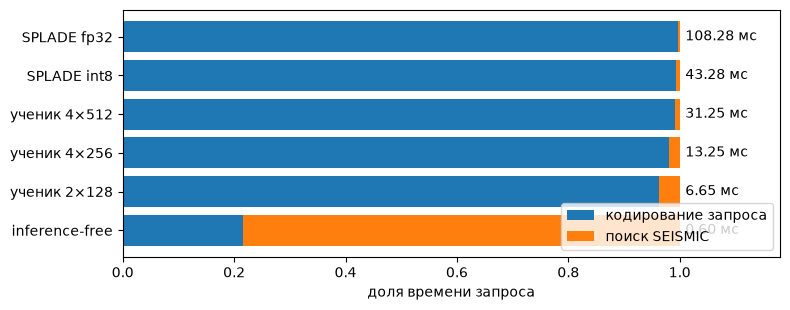

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# сквозные замеры (e2e_report.txt, e2e_report_if.txt, distill_eval.txt), мс на запрос, медианы
e2e = {
    "SPLADE fp32":     (108.0, 0.28),
    "SPLADE int8":     (43.0, 0.28),
    "ученик 4×512":    (31.0, 0.25),
    "ученик 4×256":    (13.0, 0.25),
    "ученик 2×128":    (6.4, 0.25),
    "inference-free":  (0.13, 0.47),
}
names = list(e2e)
enc = np.array([e2e[n][0] for n in names])
srch = np.array([e2e[n][1] for n in names])

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(names, enc / (enc + srch), label="кодирование запроса")
ax.barh(names, srch / (enc + srch), left=enc / (enc + srch), label="поиск SEISMIC")
ax.set_xlabel("доля времени запроса"); ax.invert_yaxis(); ax.legend(loc="lower right")
for i, (e, s) in enumerate(zip(enc, srch)):
    ax.text(1.01, i, f"{e + s:.2f} мс", va="center")
ax.set_xlim(0, 1.18); plt.tight_layout(); plt.show()

Вывод: при одиночных запросах SPLADE ускорять нужно кодировщик (ученики, int8, GPU). Это направление уже исследовано
(Li-LSR, arXiv 2505.01452). У inference-free модели кодирование сводится к токенизации, и **узким местом становится поиск**.
Именно им мы и занимаемся.

## 2. SEISMIC и патч `search_adaptive`

Как SEISMIC обрабатывает запрос:
* берёт `query_cut` термов запроса с наибольшими весами;
* для каждого терма проходит его постинг-лист. Лист разбит на блоки с «summary»-вектором, и блок пропускается, если его
  верхняя оценка скора ниже `heap_factor × (k-й скор в куче)`;
* `query_cut` и `heap_factor` **одинаковы для всех запросов** и подбираются под целевую полноту.

Что добавляет патч (`src/inverted_index.rs`, `search_with_stop`): после обработки каждого терма, начиная с `min_terms`-го,
проверяется, насколько вырос k-й скор в куче. Если относительный прирост ≤ `stop_eps`, обход прекращается.
Так каждый запрос сам выбирает свою глубину. Если остановку выключить, результат совпадает с обычным `search`.

```text
heap = []
for t, (term, w) in enumerate(sorted(query, by=-w)[:query_cut]):
    kth_before = heap.kth()
    scan_blocks(term, w, heap, heap_factor)
    if t + 1 >= min_terms and (heap.kth() - kth_before) <= stop_eps * kth_before:
        break
```

Интуиция: когда k-й скор перестал расти, оставшиеся термы почти наверняка уже не поменяют top-k.

## 3. Форма весов запроса: на чём держится гипотеза

Механизм, который мы предполагаем:
* у SPLADE вес запроса сосредоточен в нескольких термах. Первые термы сразу поднимают k-й скор, после этого блочная отсечка
  (`heap_factor`) работает эффективно, и хвост дешёвый. Фиксированный `query_cut` уже почти оптимален, адаптивной остановке экономить нечего;
* у inference-free веса ровные (IDF). Порог кучи растёт медленно, проходится больше блоков, и момент, когда top-k
  стабилизировался, сильно различается между запросами. Поэтому остановка, подстроенная под запрос, окупается.

Ниже код описывает форму весов на настоящих векторах dev-запросов: сколько в запросе термов, какая доля массы
приходится на первые r термов, коэффициент Джини. Ячейка рассчитана на запуск на сервере (`/data/konkovani`),
без файлов она пропускается.


SPLADE: нет /data/konkovani/msmarco_200000_enc/queries.npz, пропускаю
inference-free: нет /data/konkovani/msmarco_200000_if/queries.npz, пропускаю


C:\Users\ninak\AppData\Local\Temp\ipykernel_15136\1523646564.py:30: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(); plt.tight_layout(); plt.show()


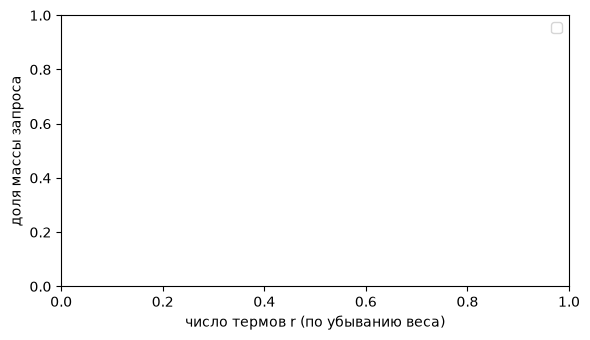

In [2]:
import os
import scipy.sparse as sp

DATA = "/data/konkovani"
sets = {"SPLADE": f"{DATA}/msmarco_200000_enc/queries.npz",
        "inference-free": f"{DATA}/msmarco_200000_if/queries.npz"}

def gini(w):
    w = np.sort(w); n = len(w)
    return (2 * np.arange(1, n + 1) - n - 1) @ w / (n * w.sum()) if n > 1 else 0.0

R = 20
fig, ax = plt.subplots(figsize=(6, 3.5))
for name, path in sets.items():
    if not os.path.exists(path):
        print(f"{name}: нет {path}, пропускаю"); continue
    Q = sp.load_npz(path).tocsr()
    nnz, mass, g = [], np.full((Q.shape[0], R), np.nan), []
    for i in range(Q.shape[0]):
        w = np.sort(Q.data[Q.indptr[i]:Q.indptr[i + 1]])[::-1]
        if len(w) == 0: continue
        nnz.append(len(w)); g.append(gini(w))
        c = np.cumsum(w) / w.sum()
        mass[i] = np.concatenate([c, np.ones(max(0, R - len(c)))])[:R]
    m = np.nanmean(mass, axis=0)
    print(f"{name:15s}: термов {np.mean(nnz):5.1f} (медиана {np.median(nnz):.0f}), "
          f"масса в top-3 {m[2]:.2f}, Джини {np.mean(g):.2f}")
    ax.plot(np.arange(1, R + 1), m, marker="o", ms=3, label=name)
ax.set_xlabel("число термов r (по убыванию веса)"); ax.set_ylabel("доля массы запроса")
ax.legend(); plt.tight_layout(); plt.show()

## 4. Результаты в настоящем SEISMIC (MS MARCO 200k)

Методика:
* полнота@10 считается относительно точного top-10 той же модели;
* задержка измеряется в один поток, берётся минимум из 3 повторов;
* параметры подбираются на половине запросов (tune), числа считаются на другой половине (test), разбиение повторяется с 3 seed;
* 95% bootstrap CI по запросам;
* **ratio** = задержка метода / задержка лучшей фиксированной настройки обычного SEISMIC при той же полноте (по фронту Парето).

In [3]:
import pandas as pd
res = pd.DataFrame({
    "метод": ["оракул (верхняя граница)", "линейный предсказатель query_cut", "gamma-cut (доля массы)",
              "патч search_adaptive"],
    "SPLADE": ["~0.72", "~1.00", "~1.0", "≥0.97, незначимо"],
    "inference-free, полнота 0.90": ["0.70", "0.93", "1.04", "0.88 [0.86, 0.90]"],
    "inference-free, 0.95": ["0.64", "0.98", "1.05", "0.90 [0.85, 0.94]"],
    "inference-free, 0.97": ["—", "0.95", "—", "0.85 [0.79, 0.87]"],
}).set_index("метод")
res

,SPLADE,"inference-free, полнота 0.90","inference-free, 0.95","inference-free, 0.97"
метод,,,,
оракул (верхняя граница),~0.72,0.70,0.64,—
линейный предсказатель query_cut,~1.00,0.93,0.98,0.95
gamma-cut (доля массы),~1.0,1.04,1.05,—
патч search_adaptive,"≥0.97, незначимо","0.88 [0.86, 0.90]","0.90 [0.85, 0.94]","0.85 [0.79, 0.87]"


* Патч значимо ускоряет поиск на inference-free векторах: CI < 1 во всех 3 seed, p95 тоже лучше (0.83–0.92).
* На SPLADE выигрыш не больше 3% и незначим.
* Оракул показывает, что запас для подстройки под запрос есть у обеих моделей. Но у SPLADE реализуемые методы его не выбирают.
* Лучшие настройки на inference-free: `query_cut` 15–20, `heap_factor` 0.95–1.0, `stop_eps` 0.001–0.05, `min_terms` 2–3.

**Где новизна:** адаптивная остановка известна для плотных векторов (Busolin et al. CIKM 2024, DARTH, LAET).
Для кластеризованного разреженного индекса (SEISMIC, Superblock Pruning, LSP) параметры везде фиксированные.
Наш вклад: адаптивная остановка в SEISMIC и то, что её польза **зависит от типа модели** через форму весов запроса.

## 5. Причинная проверка и дальнейшие шаги

**Sharpen-эксперимент** (`sharpen_eval.py`, `run_sharpen.sh`): документы не меняются, веса запроса возводятся в степень p.
* Если механизм верный, у inference-free при p = 2, 3 (веса становятся острее) выигрыш патча должен **падать**.
* У SPLADE при p < 1 (веса становятся ровнее) выигрыш должен **появиться**.
* Результаты: `sharpen_if.txt`, `sharpen_splade.txt` на сервере.

**Кривые «скорость — качество»** (`pareto_eval.py`): адаптивный поиск против подбора гиперпараметров SEISMIC,
по полноте и по MRR. Результаты в `pareto_if.*` и `pareto_splade.*`.

**Что дальше**:
1. Подкорпус 1M, затем полный MS MARCO 8.8M: растёт ли эффект с размером корпуса.
2. Ещё 2–3 inference-free модели: OpenSearch v3, Li-LSR.
3. Остановка по блокам (`block_patience`, `seismic_block_eval.py`) и её сочетание с остановкой по термам.
4. 2–3 датасета BEIR, чтобы проверить работу вне домена.
5. Счётчик просмотренных блоков в патче: прямое подтверждение механизма.